In [ ]:
# look mlpmakemore.ipynb for the detailed comments.
import torch
import matplotlib.pyplot as plt
%matplotlib inline
words = open('names.txt', 'r').read().splitlines()

In [3]:
char = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(char)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

In [4]:
#making training set, validation set and test set
def build_dataset(words, block_size=4):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix] #crop and append
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(f"X.shape: {X.shape}, Y.shape: {Y.shape}")
    return X, Y
import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xv, Yv = build_dataset(words[n1:n2]) # 10% after training set
Xt, Yt = build_dataset(words[n2:]) # 10% after validation set

X.shape: torch.Size([182625, 4]), Y.shape: torch.Size([182625])
X.shape: torch.Size([22655, 4]), Y.shape: torch.Size([22655])
X.shape: torch.Size([22866, 4]), Y.shape: torch.Size([22866])


In [5]:
# linear layer -> y = W * A.T + b
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):  # when using batch normalization we don't need bias so thats why option to false it!
        self.weight = torch.randn((fan_in, fan_out)) / fan_in ** 0.5  # in the example above fan_in is block_size * embedding_size and fan_out is hidden_size
        if bias == True: self.bias = torch.zeros(fan_out)  
        else: self.bias = None
    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None: self.out += self.bias
        return self.out
    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])

In [6]:
class BatchNorm1d:
    def __init__(self, dim, eps = 1e-5, momentum = 0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        # learnable params
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        #running buffers
        self.mean_running = torch.zeros(dim)
        self.var_running = torch.ones(dim)

    def __call__(self, x):
        if self.training is True:  # if training is True then we will calculate the mean and std of the current batch and update the running mean and std
            xmean = x.mean(0, keepdim=True)
            xvar = x.var(0, keepdim=True) 
        else: #if not training we want to use the running mean and std for inference
            xmean = self.mean_running
            xvar = self.var_running
        xhat = (x - xmean) / (xvar + self.eps) ** 0.5
        self.out = self.gamma * xhat  + self.beta
        if self.training: 
            with torch.no_grad():
                self.mean_running = (1 - self.momentum) * self.mean_running  + self.momentum * xmean
                self.var_running = (1 - self.momentum) * self.var_running + self.momentum * xvar
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]



class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []     


In [7]:
block_size = 4
embedding_size = 10
hidden_size = 200
C = torch.randn((len(stoi), embedding_size), requires_grad=True)
layers = [
    Linear(block_size * embedding_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, len(stoi), bias=False), BatchNorm1d(len(stoi)),
]

with torch.no_grad():
    layers[-1].gamma *= 0.1
    # layers[-1].weight *= 0.1  introduced batchnorm so gamma fix better hehe
    for layer in layers:
        if isinstance(layer, Linear):
            layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()] 
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

175724


In [16]:
max_steps = 20000
batch_size = 32
lossi = []
ud = [] # used to store the update direction (i.e how much change in the parameters)
torch.set_grad_enabled(True)
for i in range(max_steps):
    ix = torch.randint(0, Xtr.shape[0], (batch_size,))
    Xb , Yb = Xtr[ix], Ytr[ix]
    #forward pass
    emb = C[Xb] #embedding characters into vectors
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = torch.nn.functional.cross_entropy(x, Yb)   # cross_entropy is L = - 1 / m  sum over m(log(softmax(x)))

    #backward pass
    for layer in layers:
        layer.out.retain_grad() # retain the gradient of the output of each layer for backpropagation
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.01 if i < 15000 else 0.001
    for p in parameters:
        p.data -= lr * p.grad

    lossi.append(loss.log10().item())
    with torch.no_grad():
        ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters]) 

    if i % 10000 == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    #if i > 1000: break

      0/  20000: 2.0987
  10000/  20000: 1.9356


layer 2 (      Tanh): mean +0.00, std 0.61, saturated 3.83%
layer 5 (      Tanh): mean -0.02, std 0.64, saturated 4.17%
layer 8 (      Tanh): mean -0.01, std 0.66, saturated 4.64%
layer 11 (      Tanh): mean -0.01, std 0.68, saturated 5.30%
layer 14 (      Tanh): mean -0.01, std 0.68, saturated 5.44%


Text(0.5, 1.0, 'activation distribution')

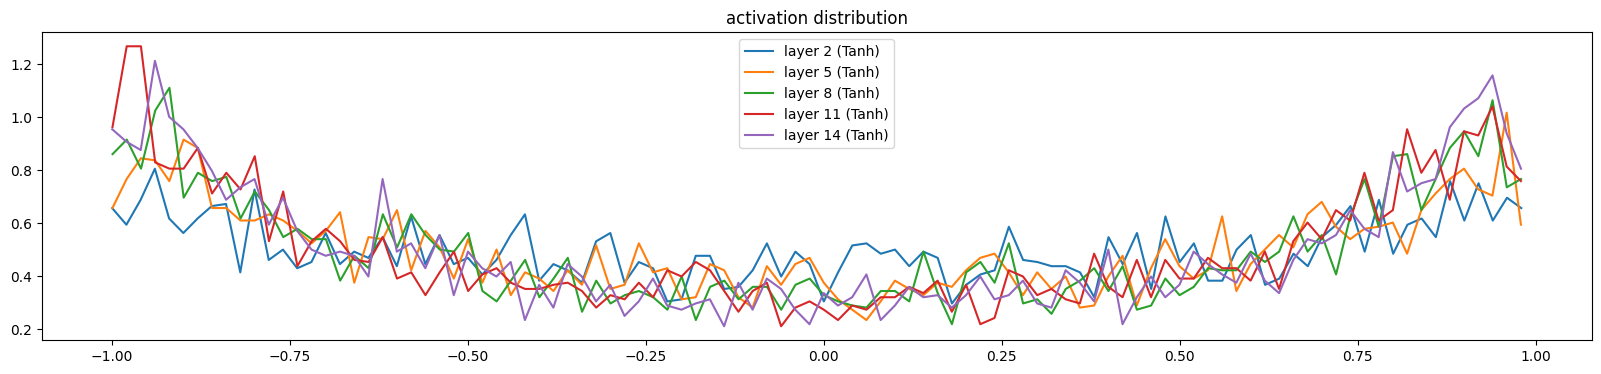

In [17]:
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers):
    if isinstance(layer, Tanh):
        t = layer.out.detach()
        print('layer %d (%10s): mean %+.2f, std %.2f, saturated %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title("activation distribution")

layer 2 (      Tanh): mean -1.05e-04, std 4.03e-03
layer 5 (      Tanh): mean -2.77e-05, std 3.65e-03
layer 8 (      Tanh): mean -1.87e-05, std 3.60e-03
layer 11 (      Tanh): mean +5.35e-05, std 3.55e-03
layer 14 (      Tanh): mean +5.50e-05, std 3.43e-03


Text(0.5, 1.0, 'gradient distribution')

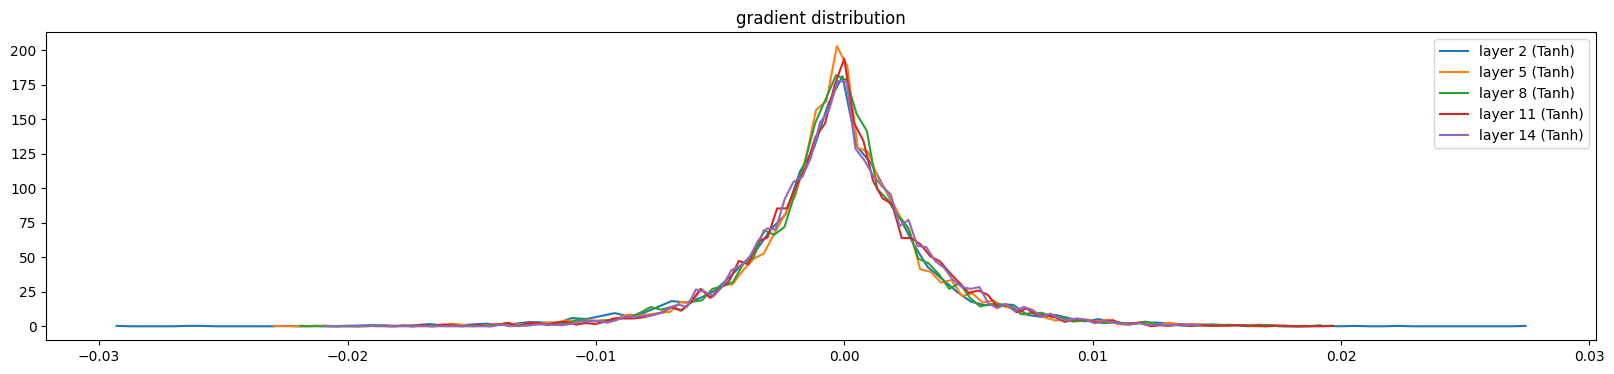

In [18]:
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers):
    if isinstance(layer, Tanh):
        t = layer.out.grad
        print('layer %d (%10s): mean %+.2e, std %.2e' % (i, layer.__class__.__name__, t.mean(), t.std()))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title("gradient distribution")

weight   (27, 10) | mean -0.001684 | std 1.746436e-02 || grad:data ratio 1.778046e-02
weight  (40, 200) | mean -0.000045 | std 9.720056e-03 || grad:data ratio 3.670892e-02
weight (200, 200) | mean +0.000017 | std 8.129822e-03 || grad:data ratio 6.791707e-02
weight (200, 200) | mean +0.000033 | std 8.172443e-03 || grad:data ratio 6.804207e-02
weight (200, 200) | mean -0.000008 | std 7.773092e-03 || grad:data ratio 6.531302e-02
weight (200, 200) | mean -0.000029 | std 7.366304e-03 || grad:data ratio 6.164740e-02
weight  (200, 27) | mean +0.000438 | std 1.822818e-02 || grad:data ratio 1.430933e-01


Text(0.5, 1.0, 'weights gradient distribution')

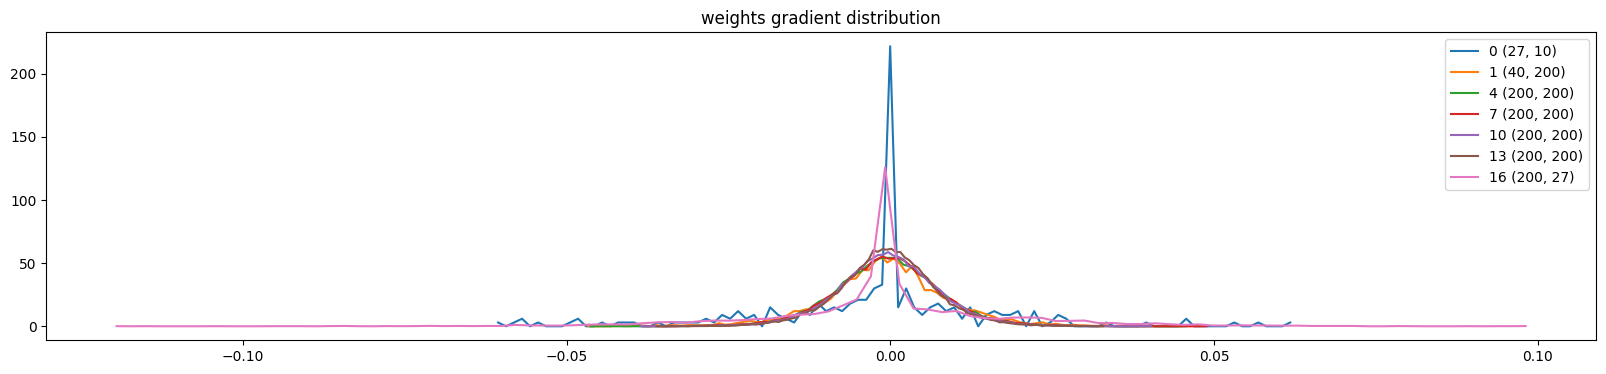

In [19]:
plt.figure(figsize=(20, 4))
legends = []
for i, p in enumerate(parameters):
    t = p.grad
    if p.ndim == 2: # only plot for weight matrices, not biases
        print('weight %10s | mean %+f | std %e || grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution')

Text(0.5, 1.0, 'learning rate update ratio over time')

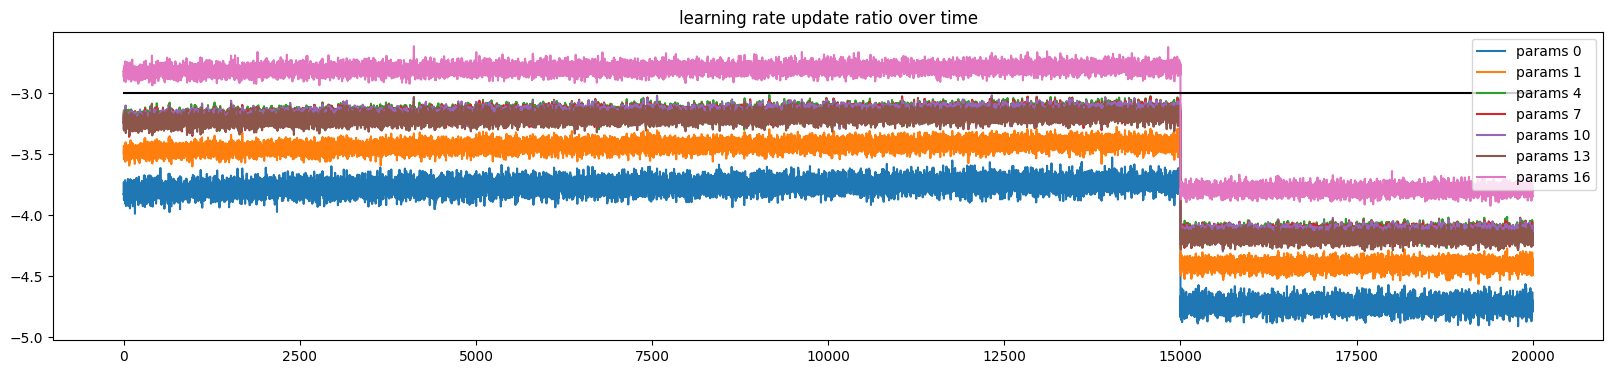

In [20]:
plt.figure(figsize=(20, 4))
legends = []
for i, p in enumerate(parameters):
    if p.ndim == 2:
        plt.plot([ud[j][i] for j in range(len(ud))])
        legends.append('params %d' % i)

plt.plot([0, len(ud)], [-3, -3], 'k')
plt.legend(legends)
plt.title('learning rate update ratio over time')

In [21]:
import torch.nn.functional as F
@torch.no_grad()
def evaluate(split):
    x,y = {
    'train': (Xtr, Ytr),
    'val': (Xv, Yv),
    'test': (Xt, Yt),
    }[split]
    emb = C[x]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, y)
    print(split, loss.item())
for layer in layers:
  layer.training = False
evaluate('train')
evaluate('val')
evaluate('test')

train 2.040154457092285
val 2.0982327461242676
test 2.0980613231658936


In [22]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      emb = C[torch.tensor([context])] # (1,block_size,n_embd)
      x = emb.view(emb.shape[0], -1) # concatenate the vectors
      for layer in layers:
        x = layer(x)
      logits = x
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out)) # decode and print the generated word

carlah.
amelle.
khitmri.
reily.
skan.
saeja.
hubedephirac.
kaqui.
nellarah.
maiir.
kaleigh.
hamondin.
quinn.
shon.
malia.
biri.
jerogierryn.
kaileenius.
bren.
edii.
